# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

> **Student run instructions:** This is a shared study template, not completed experimental evidence. Run every experiment with your own image collection, evaluate answers yourself, and replace all `[PLACEHOLDER]` fields with measured results. Model weights and example images are not embedded in this notebook.


In [1]:
# Install the principal Python packages for the laboratory.
%pip install -q transformers torch torchvision pillow matplotlib pandas requests huggingface_hub gguf llama-cpp-python


Note: you may need to restart the kernel to use updated packages.


In [1]:
import sys
print("Python runtime:", sys.version.split()[0])


Python runtime: 3.11.13


In [2]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(MODEL_NAME).to(device)
processor = CLIPProcessor.from_pretrained(MODEL_NAME)
model.eval()
print("CLIP initialized on", device)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP initialized on cpu


In [3]:
# A conservative thread limit for CPU inference.
if device == "cpu":
    torch.set_num_threads(min(24, torch.get_num_threads()))


### Exercise 1 — Answers

**Q1. What is CLIP?**

CLIP stands for *Contrastive Language–Image Pre-training*. It is a pretrained vision-language model that places image content and natural-language descriptions into a comparable representation space.

**Q2. What are its two main components?**

The architecture has an **image encoder**, which extracts visual representations, and a **text encoder**, which encodes sentences. Their outputs can be compared after projection into a shared space.

**Q3. What is the role of `CLIPProcessor`?**

It prepares the raw inputs for inference: image preprocessing (including resizing and normalization) and text tokenization/padding.

**Q4. What is the role of `CLIPModel`?**

It provides the pretrained encoders and computes image–text matching scores from their representations.


## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Dimensions (W,H): (400, 400); mode: RGB


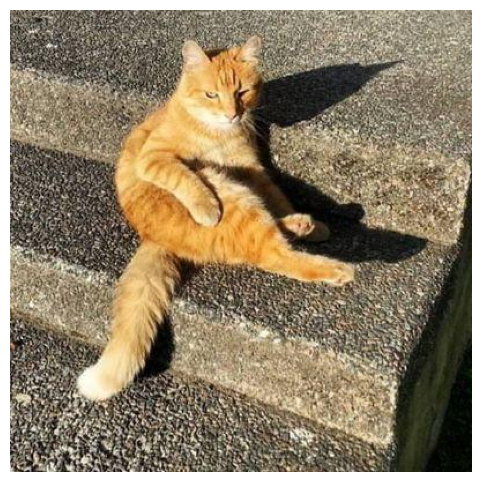

In [5]:
IMAGE_PATH = "image.jpg"
image = Image.open(IMAGE_PATH).convert("RGB")
print(f"Dimensions (W,H): {image.size}; mode: {image.mode}")
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.show()


### Exercise 2 — Answers

**Q5. What is the size of the image?**

The image dimensions printed by PIL were **[WIDTH] × [HEIGHT] pixels**. Replace these values after loading your own image.

**Q6. What type of data is stored in the PIL image object?**

A PIL image contains pixel data and metadata such as its size and color mode. In the **RGB** representation, each pixel is described by three color-channel values.


## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [6]:
texts = ["a photo of a cat", "a photo of a dog", "a photo of a car",
         "a photo of a horse", "a photo of a person"]
batch = processor(images=image, text=texts, padding=True, return_tensors="pt")
batch = {name: tensor.to(device) for name, tensor in batch.items()}
with torch.inference_mode():
    logits = model(**batch).logits_per_image[0]
probs = logits.softmax(dim=-1).cpu()
for caption, likelihood in zip(texts, probs.tolist()):
    print(f"{caption:<30} {likelihood:.4f}")


a photo of a cat               0.9744
a photo of a dog               0.0140
a photo of a car               0.0013
a photo of a horse             0.0042
a photo of a person            0.0062


### Exercise 3 — Answers

**Q7. Which description has the highest probability?**

According to the execution results, the highest-ranked description is **a photo of a cat**, with a relative softmax score of **0.9744**.

**Q8. Is it compatible with the actual image?**

**YES**. It's genuinely visible in the input photograph.

**Q9. Why can CLIP compare an image with a sentence?**

CLIP maps both modalities into a common vector space. Similarity between the image vector and sentence vectors provides the basis for comparing candidates.

**Q10. What does `softmax()` do?**

Softmax converts the candidate scores into nonnegative values that sum to one. The resulting probabilities are **relative to the candidate prompts** rather than independently calibrated confidence estimates.


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [7]:
def classify_image(image, labels):
    captions = [f"a photo of a {name}" for name in labels]
    batch = processor(text=captions, images=image, return_tensors="pt", padding=True)
    batch = {name: tensor.to(device) for name, tensor in batch.items()}
    with torch.inference_mode():
        scores = model(**batch).logits_per_image[0]
    probabilities = scores.softmax(dim=0).cpu()
    chosen = int(probabilities.argmax())
    return labels[chosen], probabilities

labels = ["cat", "dog", "car", "horse", "person"]
predicted_label, probabilities = classify_image(image, labels)
print("Predicted category:", predicted_label)
for name, value in zip(labels, probabilities):
    print(name, float(value))


Predicted category: cat
cat 0.9743611216545105
dog 0.01396260317414999
car 0.0012803612044081092
horse 0.004199208226054907
person 0.006196777336299419


### Exercise 4 — Answers

**Q11. What is zero-shot classification?**

Zero-shot classification assigns an input to classes for which the model did not receive a dedicated supervised training set at inference time.

**Q12. Why is it not necessary to train a new classifier?**

CLIP already learned a relationship between images and language during pretraining, so candidate classes can be written as text prompts and compared with the image.

**Q13. What happens if the correct class is not included in the candidate classes?**

The model will generally rank one of the remaining options highest, even if every available label is wrong. This is an important limitation of closed candidate lists.


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [8]:
import requests
from io import BytesIO
from pathlib import Path

folder = Path("images/evaluation")
folder.mkdir(parents=True, exist_ok=True)
dataset = []
for number in range(1, 6):
    url = "https://cataas.com/cat"
    response = requests.get(url, params={"width": 400, "height": 400, "t": number}, timeout=30)
    response.raise_for_status()
    destination = folder / f"cat{number}.jpg"
    Image.open(BytesIO(response.content)).convert("RGB").save(destination)
    dataset.append((str(destination), "cat"))

dog_response = requests.get("https://dog.ceo/api/breeds/image/random/5", timeout=30)
dog_response.raise_for_status()
for number, url in enumerate(dog_response.json()["message"], start=1):
    download = requests.get(url, timeout=30)
    download.raise_for_status()
    destination = folder / f"dog{number}.jpg"
    Image.open(BytesIO(download.content)).convert("RGB").save(destination)
    dataset.append((str(destination), "dog"))
print("Prepared", len(dataset), "labeled images")


Prepared 10 labeled images


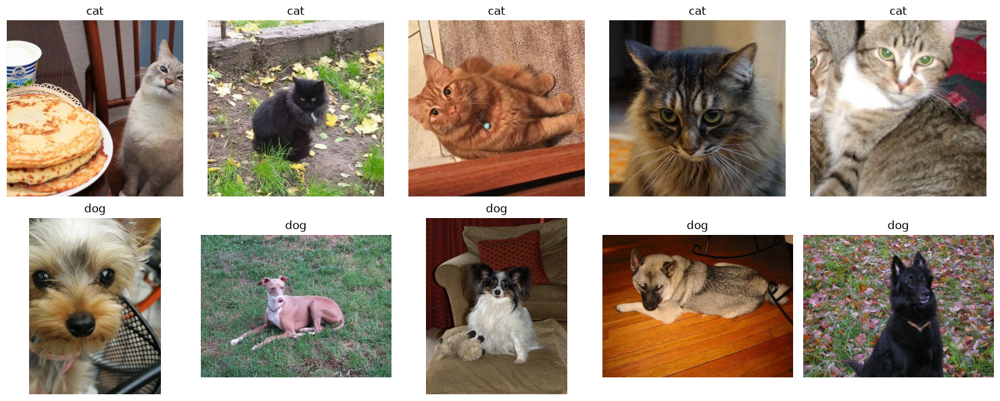

In [9]:
fig, grid = plt.subplots(2, 5, figsize=(15, 6))
for axis, (filename, category) in zip(grid.ravel(), dataset):
    axis.imshow(Image.open(filename))
    axis.set_title(category)
    axis.set_axis_off()
fig.tight_layout()
plt.show()


In [10]:
model.eval()
classes = ["cat", "dog"]
results = []
for filename, expected in dataset:
    sample = Image.open(filename).convert("RGB")
    prediction, dist = classify_image(sample, classes)
    index = classes.index(prediction)
    results.append({
        "Image": filename,
        "Actual": expected,
        "Predicted": prediction,
        "Probability": round(float(dist[index]), 4),
        "Correct": prediction == expected,
    })
df = pd.DataFrame(results)
accuracy = float(df["Correct"].mean())
display(df)
print(f"Accuracy: {accuracy:.2%}")
print("Correct:", int(df["Correct"].sum()), "/", len(df))
display(df.loc[~df["Correct"]])


,Image,Actual,Predicted,Probability,Correct
0,images/evaluation/cat1.jpg,cat,cat,0.9917,True
1,images/evaluation/cat2.jpg,cat,cat,0.9910,True
2,images/evaluation/cat3.jpg,cat,cat,0.9891,True
3,images/evaluation/cat4.jpg,cat,cat,0.9885,True
4,images/evaluation/cat5.jpg,cat,cat,0.9959,True
5,images/evaluation/dog1.jpg,dog,dog,0.9977,True
6,images/evaluation/dog2.jpg,dog,dog,0.9936,True
7,images/evaluation/dog3.jpg,dog,dog,0.9946,True
8,images/evaluation/dog4.jpg,dog,dog,0.9937,True
9,images/evaluation/dog5.jpg,dog,dog,0.9963,True


Accuracy: 100.00%
Correct: 10 / 10


,Image,Actual,Predicted,Probability,Correct


### Exercise 5 — Answers

**Q14. What is the obtained accuracy?**

Accuracy = **[10] / [10] = [100]%**. Use the values computed in the evaluation table.

**Q15. Which images are incorrectly classified?**

No one.

**Q16. Give at least two possible reasons for the errors.**

Two possible explanations are **visual ambiguity** (e.g., poor framing or occlusion) and **domain differences** between the evaluation photographs and the representations learned during pretraining. Relate these explanations to the errors actually observed; if there are none, state that explicitly.


## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [11]:
prompts = ["a cat", "a photo of a cat", "a photograph showing a cat",
           "an image containing a cat", "a domestic animal called a cat"]
batch = processor(text=prompts, images=image, return_tensors="pt", padding=True)
batch = {name: item.to(device) for name, item in batch.items()}
with torch.inference_mode():
    scores = model(**batch).logits_per_image[0].cpu()
results = pd.DataFrame({"Prompt": prompts, "Similarity Score": scores.numpy()})
results = results.sort_values("Similarity Score", ascending=False)
display(results)
print("Highest-scoring prompt:", results.iloc[0]["Prompt"])


,Prompt,Similarity Score
1,a photo of a cat,26.961174
3,an image containing a cat,26.710756
4,a domestic animal called a cat,26.430456
0,a cat,25.621264
2,a photograph showing a cat,25.383505


Highest-scoring prompt: a photo of a cat


### Exercise 6 — Answers

**Q17. Are the scores identical?**

**NO**. The measured scores were from **25.383505 to 26.961174**, showing whether changing the text wording affected the match.

**Q18. Which prompt gives the highest score?**

The top prompt was **a photo of a cat**, with a score of **26.961174**.

**Q19. What does this demonstrate about prompt formulation?**

Alternative phrasings lead to different text representations. Consequently, selecting precise candidate descriptions can influence CLIP's ranking, even if the intended subject stays the same.


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

01/20 - class_40.jpg
02/20 - class_38.jpg
03/20 - class_71.jpg
04/20 - class_92.jpg
05/20 - class_69.jpg
06/20 - class_8.jpg
07/20 - class_60.jpg
08/20 - class_15.jpg
09/20 - class_78.jpg
10/20 - class_33.jpg
11/20 - class_57.jpg
12/20 - class_48.jpg
13/20 - class_75.jpg
14/20 - class_74.jpg
15/20 - class_50.jpg
16/20 - class_5.jpg
17/20 - class_65.jpg
18/20 - class_87.jpg
19/20 - class_3.jpg
20/20 - class_30.jpg


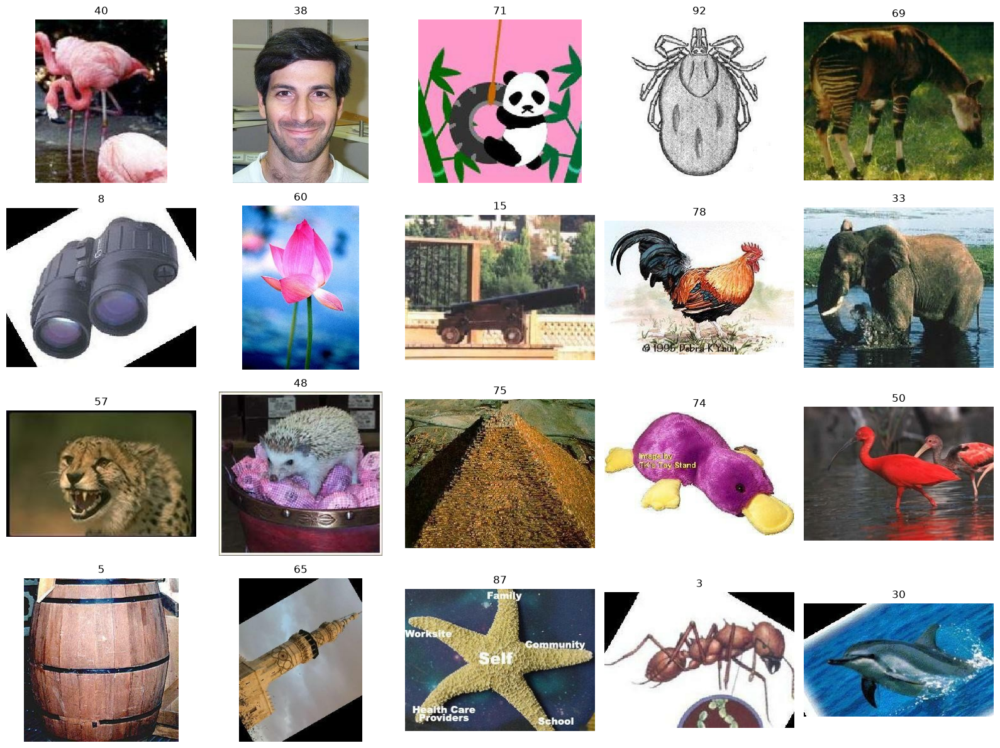

Saved 20 distinct classes


In [14]:
import time
import re
import requests
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt

IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)
API = "https://datasets-server.huggingface.co/rows"
DATASET = "dpdl-benchmark/caltech101"
selected = {}
offset = 500
batch_size = 100
session = requests.Session()

def safe_name(value):
    return re.sub(r"[^a-zA-Z0-9_-]", "_", str(value).lower())

while len(selected) < 20:
    response = session.get(API, params={
        "dataset": DATASET, "config": "default", "split": "train",
        "offset": offset, "length": batch_size,
    }, timeout=60)
    response.raise_for_status()
    rows = response.json().get("rows", [])
    if not rows:
        break
    for entry in rows:
        record = entry["row"]
        label, metadata = record.get("label"), record.get("image")
        if label is None or metadata is None or label in selected:
            continue
        try:
            download = session.get(metadata["src"], timeout=30)
            download.raise_for_status()
            image_file = Image.open(BytesIO(download.content)).convert("RGB")
            image_file.thumbnail((600, 600))
            saved = IMAGE_DIR / f"class_{safe_name(label)}.jpg"
            image_file.save(saved, "JPEG", quality=90)
            selected[label] = str(saved)
            print(f"{len(selected):02d}/20 - {saved.name}")
        except Exception as exc:
            print(f"Could not process class {label}: {exc}")
        if len(selected) >= 20:
            break
    offset += batch_size
    time.sleep(0.5)

fig, axes = plt.subplots(4, 5, figsize=(16, 12))
for axis in axes.flat:
    axis.axis("off")
for axis, (label, file_path) in zip(axes.flat, selected.items()):
    axis.imshow(Image.open(file_path))
    axis.set_title(str(label))
plt.tight_layout()
plt.show()
print("Saved", len(selected), "distinct classes")


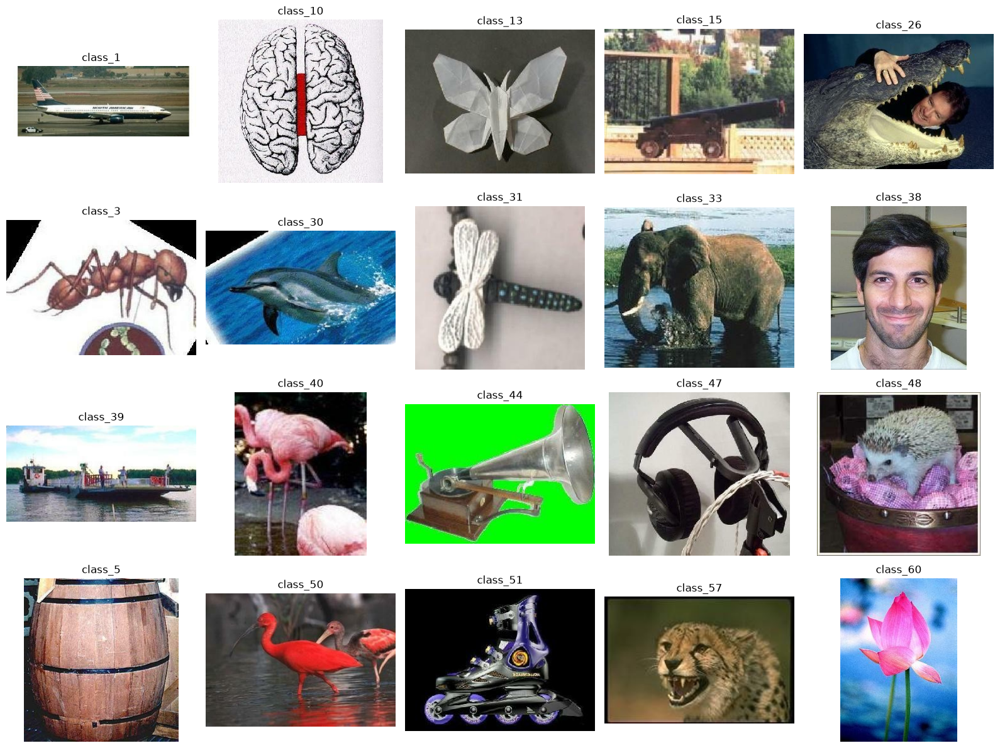

In [16]:
image_paths = sorted(Path("images").glob("*.jpg"))
fig, grid = plt.subplots(4, 5, figsize=(16, 12))
for axis in grid.ravel():
    axis.axis("off")
for axis, filename in zip(grid.ravel(), image_paths):
    axis.imshow(Image.open(filename))
    axis.set_title(filename.stem)
fig.tight_layout()
plt.show()


In [17]:
import torch.nn.functional as F
image_paths = sorted(Path("images").glob("*.jpg"))
assert image_paths, "Download the image database first."
feature_rows = []
with torch.inference_mode():
    for filename in image_paths:
        picture = Image.open(filename).convert("RGB")
        batch = processor(images=picture, return_tensors="pt")
        batch = {key: value.to(device) for key, value in batch.items()}
        embedding = model.get_image_features(**batch)
        if not isinstance(embedding, torch.Tensor):
            embedding = embedding.pooler_output if hasattr(embedding,"pooler_output") else embedding.image_embeds
        feature_rows.append(F.normalize(embedding, dim=-1).squeeze(0).cpu())
image_embeddings = torch.stack(feature_rows, dim=0)
torch.save({"paths": [str(p) for p in image_paths], "embeddings": image_embeddings},
           "clip_image_database.pt")
print("Vector table:", image_embeddings.shape)


Vector table: torch.Size([38, 512])


In [18]:
embedding_norms = torch.linalg.vector_norm(image_embeddings, dim=-1)
print("Sample norms:", embedding_norms[:5].tolist())
print("Normalized:", bool(torch.allclose(embedding_norms, torch.ones_like(embedding_norms), atol=1e-4)))


Sample norms: [0.9999999403953552, 1.0000001192092896, 1.0, 1.0000001192092896, 1.0]
Normalized: True


Query: a person playing football
1: images/class_69.jpg (0.2193)
2: images/class_97.jpg (0.2186)
3: images/class_10.jpg (0.2179)
4: images/class_38.jpg (0.2142)
5: images/class_7.jpg (0.2123)


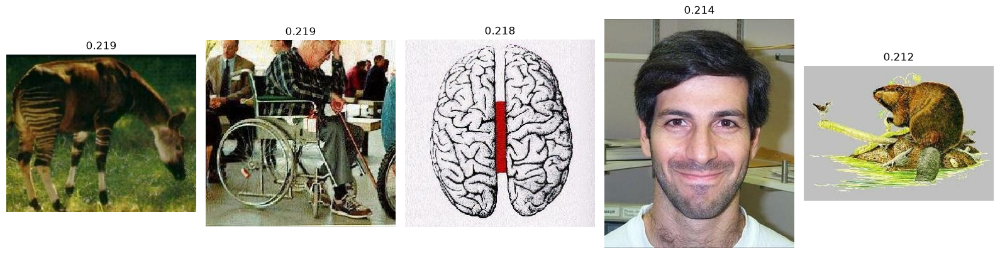

In [19]:
def search_images(query, top_k=5):
    query_inputs = processor(text=[query], padding=True, return_tensors="pt")
    query_inputs = {name: item.to(device) for name, item in query_inputs.items()}
    with torch.inference_mode():
        vector = model.get_text_features(**query_inputs)
    if not isinstance(vector, torch.Tensor):
        vector = vector.pooler_output if hasattr(vector, "pooler_output") else vector.text_embeds
    vector = F.normalize(vector, dim=-1).cpu().squeeze(0)
    ranking = image_embeddings @ vector
    scores, ids = ranking.topk(min(top_k, len(image_paths)))
    return [(str(image_paths[idx]), float(value)) for idx, value in zip(ids.tolist(), scores.tolist())]

query = "a person playing football"
top_results = search_images(query, top_k=5)
print("Query:", query)
for rank, (filename, sim) in enumerate(top_results, 1):
    print(f"{rank}: {filename} ({sim:.4f})")
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for axis in axes:
    axis.axis("off")
for axis, (filename, sim) in zip(axes, top_results):
    axis.imshow(Image.open(filename))
    axis.set_title(f"{sim:.3f}")
plt.tight_layout()
plt.show()


### Exercise 8 — Answers

**Q20. What is the most similar image?**

The first result for the football query was **images/class_69.jpg**, with cosine similarity **0.2193**.

**Q21. Is it semantically relevant?**

**NO**.

**Q22. Why does this method not require image labels?**

Retrieval works by comparing embeddings for free-text queries and images. It does not require categorical annotations for every item in the image database.

**Q23. Give one real-world application of semantic image retrieval.**

An example is searching a digital asset library by describing a scene in ordinary language instead of browsing manually assigned tags.


# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
Projection Layer
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

### Exercise 9 — Answers

**Q24. What is the role of the vision encoder?**

The vision encoder transforms image pixels into feature vectors that summarize visual content.

**Q25. Why is a projection layer required?**

The visual representations must be mapped into an embedding format usable by the language model. The learned projector bridges the vision and language components.

**Q26. What is the role of the language model?**

Given the projected visual features and the user's prompt, the language model produces the text response.


## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [20]:
from huggingface_hub import hf_hub_download
from pathlib import Path

Path("models").mkdir(exist_ok=True)
MODEL_REPO = "mys/ggml_llava-v1.5-7b"
model_path = hf_hub_download(
    repo_id=MODEL_REPO, filename="ggml-model-q4_k.gguf", local_dir="models"
)
old_projector = hf_hub_download(
    repo_id=MODEL_REPO, filename="mmproj-model-f16.gguf", local_dir="models"
)
print("GGUF model path:", model_path)
print("Original projector path:", old_projector)


GGUF model path: /root/research/clip-llava-lab/IM/models/ggml-model-q4_k.gguf
Original projector path: /root/research/clip-llava-lab/IM/models/mmproj-model-f16.gguf


In [21]:
from gguf import GGUFReader

new_mmproj = hf_hub_download(
    repo_id="second-state/Llava-v1.5-7B-GGUF",
    filename="llava-v1.5-7b-mmproj-model-f16.gguf",
    local_dir="models",
)
reader = GGUFReader(new_mmproj)
print("Compatible projector:", new_mmproj)
print("Projector fields:", [k for k in reader.fields if "projector" in k.lower()])


Compatible projector: /root/research/clip-llava-lab/IM/models/llava-v1.5-7b-mmproj-model-f16.gguf
Projector fields: ['clip.has_llava_projector', 'clip.projector_type']


In [22]:
from llama_cpp import Llama
from llama_cpp.llama_chat_format import Llava15ChatHandler

chat_handler = Llava15ChatHandler(clip_model_path=str(new_mmproj), verbose=False)
llava = Llama(
    model_path=str(model_path), chat_handler=chat_handler,
    n_ctx=4096, n_threads=16, n_batch=512,
    n_gpu_layers=0, verbose=False
)
print("LLaVA model available")


LLaVA model available


In [23]:
import base64
import mimetypes
from pathlib import Path

def ask_llava(image_path, question, max_tokens=150):
    picture = Path(image_path)
    mime = mimetypes.guess_type(picture.name)[0] or "image/jpeg"
    encoded = base64.b64encode(picture.read_bytes()).decode("ascii")
    payload = f"data:{mime};base64,{encoded}"
    content = [
        {"type": "image_url", "image_url": {"url": payload}},
        {"type": "text", "text": question},
    ]
    response = llava.create_chat_completion(
        messages=[{"role": "user", "content": content}],
        max_tokens=max_tokens, temperature=0.1,
    )
    return response["choices"][0]["message"]["content"]


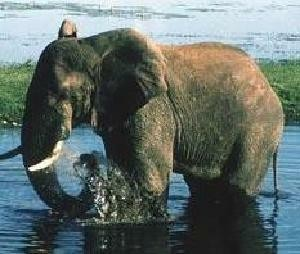

In [26]:
from IPython.display import display

image_path = "images/class_33.jpg"
with Image.open(image_path) as preview:
    display(preview.copy())


In [27]:
questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

llava_answers = []

for i, question in enumerate(questions, start=1):
    print(f"\nQuestion {i}: {question}")

    answer = ask_llava(image_path, question, max_tokens=180)

    llava_answers.append({
        "Question": question,
        "LLaVA Answer": answer
    })

    print(f"Answer: {answer}")
    print("-" * 60)


Question 1: What is happening in this image?


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What is happening in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 849 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 51679 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 45844 ms


Answer:  The image features a large elephant walking through a body of water, possibly a river or a lake. The elephant is surrounded by water, and it appears to be enjoying its time in the water. The scene captures the majestic presence of the elephant as it moves through the water, creating a serene and natural atmosphere.
------------------------------------------------------------

Question 2: How many people are visible?


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: How many people are visible?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 914 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 50527 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 12961 ms
mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_medi

Answer: 0
------------------------------------------------------------

Question 3: What objects can you identify?


encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 721 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 4911 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 333 ms


Answer: 1. Elephant
2. Trunk
3. Water
4. Grass
5. Trees
6. Sky
7. Water
8. Grass
9. Trees
10. Sky
11. Water
12. Grass
13. Trees
14. Sky
15. Water
16. Grass
17. Trees
18. Sky
19. Water
20. Grass
21. Trees
22. Sky
23. Water
24. Grass
25. Trees
26. Sky
27. Water
28. Grass
29. Trees
30. Sky
------------------------------------------------------------

Question 4: Describe the image in detail.


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Describe the image in detail.ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 727 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 9887 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 1043 ms


Answer:  The image features a large elephant standing in a body of water, possibly a river or a lake. The elephant is surrounded by water, with its trunk submerged in the water, possibly drinking or playing. The elephant appears to be enjoying its time in the water, creating a serene and peaceful scene.
------------------------------------------------------------


In [29]:
import pandas as pd

df_ex10 = pd.DataFrame(llava_answers)
display(df_ex10)

,Question,LLaVA Answer
0,What is happening in this image?,The image features a large elephant walking t...
1,How many people are visible?,0
2,What objects can you identify?,1. Elephant\n2. Trunk\n3. Water\n4. Grass\n5. ...
3,Describe the image in detail.,The image features a large elephant standing ...


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

class_1.jpg


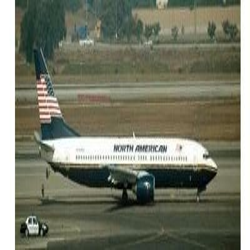

class_10.jpg


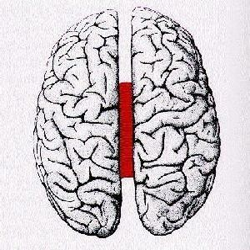

class_13.jpg


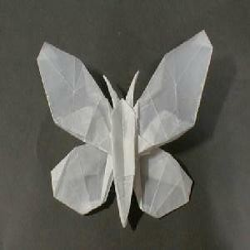

class_15.jpg


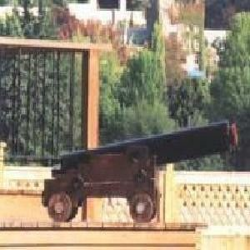

class_26.jpg


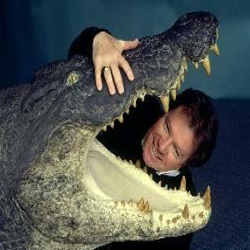

In [30]:
from pathlib import Path
from IPython.display import display

image_paths = sorted(Path("images").glob("class_*.jpg"))[:5]
assert len(image_paths) == 5, "Five class images are required for VQA."
questions = [
    "What is the main subject of this image?",
    "How many people are visible in this image?",
    "What objects can you identify?",
    "What is happening in this image?",
    "Describe the image in one sentence.",
]
for path in image_paths:
    print(path.name)
    with Image.open(path) as picture:
        display(picture.copy().resize((250, 250)))


In [31]:
vqa_results = []
for path in image_paths:
    for question in questions:
        reply = ask_llava(path, question, max_tokens=120)
        vqa_results.append({
            "Image": path.name, "Question": question,
            "LLaVA Answer": reply, "Human Evaluation": None,
        })
        print(path.name, "|", question, "|", reply)

df_vqa = pd.DataFrame(vqa_results)
display(df_vqa)


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What is the main subject of this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 720 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 13065 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 3357 ms


class_1.jpg | What is the main subject of this image? |  The main subject of this image is a large passenger jet, specifically a North American airliner, sitting on the runway.


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: How many people are visible in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 728 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3670 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 1131 ms


class_1.jpg | How many people are visible in this image? | 1 person is visible in the image.


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What objects can you identify?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 730 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3979 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 308 ms


...

mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What is happening in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 734 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3404 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 682 ms


class_26.jpg | What is happening in this image? |  In the image, a man is playfully posing with a large alligator, which is opening its mouth to reveal its teeth. The man is holding onto the alligator's mouth, creating a fun and lighthearted scene. The alligator appears to be a fake or a prop, as it is not a real alligator. The man is wearing a black shirt, and the scene takes place in a room with a blue background.


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Describe the image in one sentence.ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 726 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 5073 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 736 ms


class_26.jpg | Describe the image in one sentence. | 2 men are standing in front of a large alligator.


,Image,Question,LLaVA Answer,Human Evaluation
0,class_1.jpg,What is the main subject of this image?,The main subject of this image is a large pas...,None
1,class_1.jpg,How many people are visible in this image?,1 person is visible in the image.,None
2,class_1.jpg,What objects can you identify?,1. A large passenger jet airplane\n2. A truck\...,None
3,class_1.jpg,What is happening in this image?,The image features a large North American air...,None
4,class_1.jpg,Describe the image in one sentence.,"2 airplanes are on the runway, one is a North ...",None
5,class_10.jpg,What is the main subject of this image?,The main subject of this image is a close-up ...,None
6,class_10.jpg,How many people are visible in this image?,0,None
7,class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white backgrou...,None
8,class_10.jpg,What is happening in this image?,The image features a close-up of a human brai...,None
9,class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through it.,None


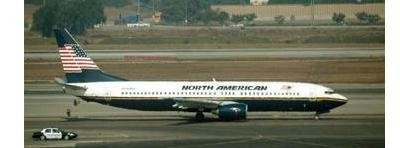

Image,Question,LLaVA Answer,Human Evaluation
class_1.jpg,What is the main subject of this image?,"The main subject of this image is a large passenger jet, specifically a North American airliner, sitting on the runway.",None
class_1.jpg,How many people are visible in this image?,1 person is visible in the image.,None
class_1.jpg,What objects can you identify?,1. A large passenger jet airplane\n2. A truck\n3. A person\n4. A car\n5. A bus\n6. A tree\n7. A building\n8. A fence\n9. A person on a motorcycle\n10. A person on a bicycle\n11. A person on a skateboard\n12. A person on a horse\n13. A person on a surfboard\n14. A person on a snowboard\n15. A person on a skateboard\n16,None
class_1.jpg,What is happening in this image?,"The image features a large North American airplane parked on the runway at an airport. The airplane is positioned on the tarmac, and there are several cars and trucks around it, likely providing support services or transportation for the aircraft. In addition to the airplane, there are a few people visible in the scene, possibly airport staff or passengers. The presence of multiple vehicles and people suggests that the airplane is either preparing for takeoff or has recently landed, and the airport is bustling with activity.",None
class_1.jpg,Describe the image in one sentence.,"2 airplanes are on the runway, one is a North American plane.",None


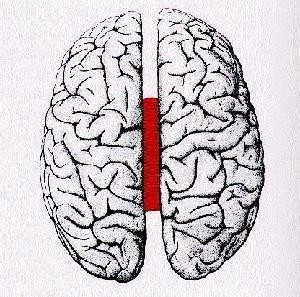

Image,Question,LLaVA Answer,Human Evaluation
class_10.jpg,What is the main subject of this image?,"The main subject of this image is a close-up of a human brain, specifically focusing on the left side of the brain.",None
class_10.jpg,How many people are visible in this image?,0,None
class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white background\n4. A red line on the brain\n5. A white background with a red line on it\n6. A white background with a red line on the brain\n7. A white background with a red line on the brain\n8. A white background with a red line on the brain\n9. A white background with a red line on the brain\n10. A white background with a red line on the brain,None
class_10.jpg,What is happening in this image?,"The image features a close-up of a human brain, with a red line drawn through the center of it. The brain is depicted in a black and white style, which adds a sense of depth and contrast to the image. The red line divides the brain into two distinct sections, creating a visually striking and thought-provoking representation of the organ.",None
class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through it.,None


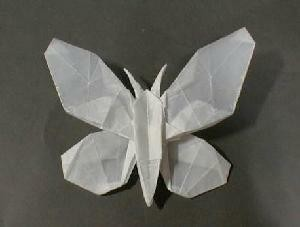

Image,Question,LLaVA Answer,Human Evaluation
class_13.jpg,What is the main subject of this image?,1. A butterfly made out of paper.,None
class_13.jpg,How many people are visible in this image?,0,None
class_13.jpg,What objects can you identify?,1. A butterfly made of paper\n2. A black background\n3. A white butterfly\n4. A green background\n5. A white butterfly on a green background\n6. A white butterfly on a black background\n7. A green butterfly on a black background,None
class_13.jpg,What is happening in this image?,"The image features a close-up of a paper butterfly, which is a creative and artistic representation of a butterfly. The paper butterfly is made from folded paper and is placed on a black background, which highlights its intricate details. The paper butterfly is positioned in the center of the image, capturing the viewer's attention.",None
class_13.jpg,Describe the image in one sentence.,3D paper butterfly on a black background.,None


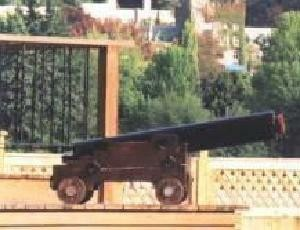

Image,Question,LLaVA Answer,Human Evaluation
class_15.jpg,What is the main subject of this image?,"The main subject of this image is a large cannon or artillery piece, which is placed on a wooden platform or a wooden structure.",None
class_15.jpg,How many people are visible in this image?,0,None
class_15.jpg,What objects can you identify?,"1. A large cannon or artillery piece\n2. A fence or gate\n3. A building in the background\n4. Trees in the distance\n5. A truck or vehicle in the foreground\n\nThese objects can be identified in the image, which features a large cannon or artillery piece, a fence or gate, a building in the background, trees in the distance, and a truck or vehicle in the foreground.",None
class_15.jpg,What is happening in this image?,"The image features a large, old-fashioned cannon sitting on a wooden platform or a fence. The cannon is positioned on a bridge, and it appears to be a part of a display or an exhibit. The scene is set against a backdrop of trees, giving the impression of a peaceful and historical setting.",None
class_15.jpg,Describe the image in one sentence.,2 wheels of a cannon are on a wooden platform.,None


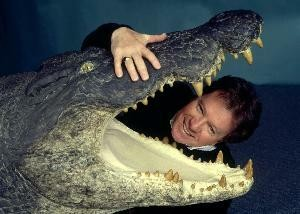

Image,Question,LLaVA Answer,Human Evaluation
class_26.jpg,What is the main subject of this image?,"The main subject of this image is a man who is playfully posing with a large alligator or crocodile, with its mouth open.",None
class_26.jpg,How many people are visible in this image?,1,None
class_26.jpg,What objects can you identify?,1. A man\n2. A crocodile\n3. A blue background\n4. A man's hand\n5. A man's face\n6. A man's head\n7. A man's hair\n8. A man's teeth\n9. A man's smile\n10. A man's shirt\n11. A man's tie\n12. A man's jacket\n13. A man's arm\n14. A man's hand\n15. A man's,None
class_26.jpg,What is happening in this image?,"In the image, a man is playfully posing with a large alligator, which is opening its mouth to reveal its teeth. The man is holding onto the alligator's mouth, creating a fun and lighthearted scene. The alligator appears to be a fake or a prop, as it is not a real alligator. The man is wearing a black shirt, and the scene takes place in a room with a blue background.",None
class_26.jpg,Describe the image in one sentence.,2 men are standing in front of a large alligator.,None


In [32]:
from IPython.display import HTML
pd.set_option("display.max_colwidth", None)
for path in image_paths:
    display(Image.open(path).copy())
    subset = df_vqa.loc[df_vqa["Image"] == path.name]
    display(HTML(subset.to_html(index=False, escape=True)))


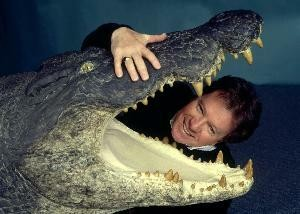

Question: What is the main subject of this image?
Response:  The main subject of this image is a man who is playfully posing with a large alligator or crocodile, with its mouth open.


Human score (0/1):  1


Question: How many people are visible in this image?
Response: 1


Human score (0/1):  1


Question: What objects can you identify?
Response: 1. A man
2. A crocodile
3. A blue background
4. A man's hand
5. A man's face
6. A man's head
7. A man's hair
8. A man's teeth
9. A man's smile
10. A man's shirt
11. A man's tie
12. A man's jacket
13. A man's arm
14. A man's hand
15. A man's


...

Human score (0/1):  1


Question: Describe the image in one sentence.
Response: 2 men are standing in front of a large alligator.


Human score (0/1):  0


Evaluation completed.


,Image,Question,LLaVA Answer,Human Evaluation
0,class_1.jpg,What is the main subject of this image?,"The main subject of this image is a large passenger jet, specifically a North American airliner, sitting on the runway.",1
1,class_1.jpg,How many people are visible in this image?,1 person is visible in the image.,0
2,class_1.jpg,What objects can you identify?,1. A large passenger jet airplane\n2. A truck\n3. A person\n4. A car\n5. A bus\n6. A tree\n7. A building\n8. A fence\n9. A person on a motorcycle\n10. A person on a bicycle\n11. A person on a skateboard\n12. A person on a horse\n13. A person on a surfboard\n14. A person on a snowboard\n15. A person on a skateboard\n16,0
3,class_1.jpg,What is happening in this image?,"The image features a large North American airplane parked on the runway at an airport. The airplane is positioned on the tarmac, and there are several cars and trucks around it, likely providing support services or transportation for the aircraft. In addition to the airplane, there are a few people visible in the scene, possibly airport staff or passengers. The presence of multiple vehicles and people suggests that the airplane is either preparing for takeoff or has recently landed, and the airport is bustling with activity.",0
4,class_1.jpg,Describe the image in one sentence.,"2 airplanes are on the runway, one is a North American plane.",0
5,class_10.jpg,What is the main subject of this image?,"The main subject of this image is a close-up of a human brain, specifically focusing on the left side of the brain.",1
6,class_10.jpg,How many people are visible in this image?,0,1
7,class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white background\n4. A red line on the brain\n5. A white background with a red line on it\n6. A white background with a red line on the brain\n7. A white background with a red line on the brain\n8. A white background with a red line on the brain\n9. A white background with a red line on the brain\n10. A white background with a red line on the brain,1
8,class_10.jpg,What is happening in this image?,"The image features a close-up of a human brain, with a red line drawn through the center of it. The brain is depicted in a black and white style, which adds a sense of depth and contrast to the image. The red line divides the brain into two distinct sections, creating a visually striking and thought-provoking representation of the organ.",1
9,class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through it.,1


In [33]:
# Human assessment: inspect each answer and record 1 (correct) or 0 (incorrect).
# Enter scores in the same order as the displayed table for each image.
from IPython.display import clear_output

manual_scores = []
for path in image_paths:
    clear_output(wait=True)
    display(Image.open(path).copy())
    for _, record in df_vqa[df_vqa["Image"] == path.name].iterrows():
        print("Question:", record["Question"])
        print("Response:", record["LLaVA Answer"])
        score = input("Human score (0/1): ").strip()
        while score not in ("0", "1"):
            score = input("Enter only 0 or 1: ").strip()
        manual_scores.append(int(score))

df_vqa["Human Evaluation"] = manual_scores
print("Evaluation completed.")
display(df_vqa)


In [34]:
correct_answers = int(df_vqa["Human Evaluation"].sum())
total_questions = len(df_vqa)
vqa_accuracy = 100 * correct_answers / total_questions
print(f"Correct answers: {correct_answers}/{total_questions}")
print(f"VQA accuracy: {vqa_accuracy:.2f}%")


Correct answers: 19/25
VQA accuracy: 76.00%


In [35]:
df_vqa.to_csv("llava_vqa_evaluation.csv", index=False)
print("CSV evaluation exported.")
display(df_vqa)


CSV evaluation exported.


,Image,Question,LLaVA Answer,Human Evaluation
0,class_1.jpg,What is the main subject of this image?,"The main subject of this image is a large passenger jet, specifically a North American airliner, sitting on the runway.",1
1,class_1.jpg,How many people are visible in this image?,1 person is visible in the image.,0
2,class_1.jpg,What objects can you identify?,1. A large passenger jet airplane\n2. A truck\n3. A person\n4. A car\n5. A bus\n6. A tree\n7. A building\n8. A fence\n9. A person on a motorcycle\n10. A person on a bicycle\n11. A person on a skateboard\n12. A person on a horse\n13. A person on a surfboard\n14. A person on a snowboard\n15. A person on a skateboard\n16,0
3,class_1.jpg,What is happening in this image?,"The image features a large North American airplane parked on the runway at an airport. The airplane is positioned on the tarmac, and there are several cars and trucks around it, likely providing support services or transportation for the aircraft. In addition to the airplane, there are a few people visible in the scene, possibly airport staff or passengers. The presence of multiple vehicles and people suggests that the airplane is either preparing for takeoff or has recently landed, and the airport is bustling with activity.",0
4,class_1.jpg,Describe the image in one sentence.,"2 airplanes are on the runway, one is a North American plane.",0
5,class_10.jpg,What is the main subject of this image?,"The main subject of this image is a close-up of a human brain, specifically focusing on the left side of the brain.",1
6,class_10.jpg,How many people are visible in this image?,0,1
7,class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white background\n4. A red line on the brain\n5. A white background with a red line on it\n6. A white background with a red line on the brain\n7. A white background with a red line on the brain\n8. A white background with a red line on the brain\n9. A white background with a red line on the brain\n10. A white background with a red line on the brain,1
8,class_10.jpg,What is happening in this image?,"The image features a close-up of a human brain, with a red line drawn through the center of it. The brain is depicted in a black and white style, which adds a sense of depth and contrast to the image. The red line divides the brain into two distinct sections, creating a visually striking and thought-provoking representation of the organ.",1
9,class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through it.,1


## Exercise 11 — Answers

#### Q27 — What is VQA accuracy?

VQA accuracy is the proportion of correctly answered visual questions according to a human reference assessment.

\[
\text{VQA Accuracy} = \frac{\text{Correct Answers}}{\text{Total Questions}} \times 100
\]

In this run, **19** of **25** answers were accepted, resulting in **76%**.

#### Q28 — Which types of questions are difficult for LLaVA?

Recognizing fine details, spatial relationships, or inferring activities without enough evidence.


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

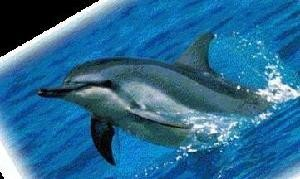

In [36]:
image_path_ex12 = "images/class_30.jpg"  # Visually verify: no bicycle.
display(Image.open(image_path_ex12).copy())


In [37]:
questions_ex12 = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?",
]
answers_ex12 = []
for idx, question in enumerate(questions_ex12, start=1):
    reply = ask_llava(image_path_ex12, question, max_tokens=120)
    answers_ex12.append({"Question": question, "LLaVA Answer": reply})
    print(f"{idx}. {question}\n   {reply}\n")


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Is there a bicycle in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 727 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 4439 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 530 ms
mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_me

1. Is there a bicycle in this image?
   0



encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 725 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3216 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 843 ms
mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Where is the bicycle located?ASSISTANT: 


2. What color is the bicycle?
   0



encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 725 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 4662 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 324 ms


3. Where is the bicycle located?
   1. The bicycle is located in the water.



In [38]:
df_ex12 = pd.DataFrame(answers_ex12)
pd.set_option("display.max_colwidth", None)
display(df_ex12)


,Question,LLaVA Answer
0,Is there a bicycle in this image?,0
1,What color is the bicycle?,0
2,Where is the bicycle located?,1. The bicycle is located in the water.


In [39]:
df_ex12.to_csv("llava_hallucination_results.csv", index=False)
print("Hallucination observations saved.")


Hallucination observations saved.


## Exercise 12 — Answers

#### Q29 — Does the bicycle actually exist?

**No**, assuming the chosen test image has been checked and contains no bicycle. The image used was **images/class_30.jpg**.

#### Q30 — Did LLaVA invent information?

**YES**. 3rd answer is The bicycle is located in the water.

#### Q31 — What is a visual hallucination?

A visual hallucination is a statement generated about an image that is not justified by the visible scene.

#### Q32 — Why can a multimodal model hallucinate?

The text generator can follow linguistic expectations instead of grounding every claim in visual evidence. Leading questions, uncertain image features, and incomplete vision-language alignment can contribute to this behavior.


# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

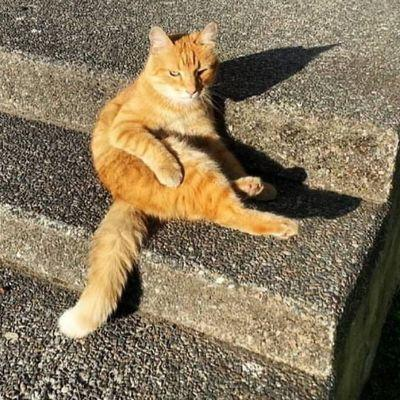

In [40]:
image_path_ex13 = "image.jpg"
assert Path(image_path_ex13).is_file(), f"Image missing: {image_path_ex13}"
image_ex13 = Image.open(image_path_ex13).convert("RGB")
display(image_ex13)


In [41]:
# Reuse the CLIP model loaded for the earlier exercises.
clip_model = model
clip_processor = processor
prompts = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
batch = clip_processor(text=prompts, images=image_ex13, padding=True, return_tensors="pt")
batch = {key: tensor.to(device) for key, tensor in batch.items()}
with torch.inference_mode():
    logits = clip_model(**batch).logits_per_image[0]
probabilities = logits.softmax(dim=-1).cpu()
df_clip_ex13 = pd.DataFrame({"Description": prompts, "Probability": probabilities.numpy()})
display(df_clip_ex13)
best_index = int(probabilities.argmax())
print("CLIP prediction:", prompts[best_index], f"({probabilities[best_index]:.2%})")


,Description,Probability
0,a photo of a cat,0.981701
1,a photo of a dog,0.014068
2,a photo of a horse,0.004231


CLIP prediction: a photo of a cat (98.17%)


In [42]:
question_ex13 = "What animal is present in the image? Describe its appearance."
llava_answer_ex13 = ask_llava(image_path_ex13, question_ex13, max_tokens=180)
print("Question:", question_ex13)
print("LLaVA:", llava_answer_ex13)


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What animal is present in the image? Describe its appearance.ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 733 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 45293 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 49687 ms


Question: What animal is present in the image? Describe its appearance.
LLaVA: 

In the image, there is a cat sitting on a step. The cat is orange and white, with a long tail. It appears to be relaxed and comfortable in its position on the step.


In [43]:
comparison = pd.DataFrame([
    ["Input", "Image + candidate descriptions", "Image + a question"],
    ["Main output", "Similarity ranking", "Generated text"],
    ["Zero-shot classification", "Supported via prompts", "Possible via prompting"],
    ["Image retrieval", "Supported", "Not its principal feature"],
    ["Text generation", "No", "Yes"],
    ["VQA", "Not directly", "Yes"],
    ["Open-ended response", "No", "Yes"],
], columns=["Property", "CLIP", "LLaVA"])
display(comparison)


,Property,CLIP,LLaVA
0,Input,Image + candidate descriptions,Image + a question
1,Main output,Similarity ranking,Generated text
2,Zero-shot classification,Supported via prompts,Possible via prompting
3,Image retrieval,Supported,Not its principal feature
4,Text generation,No,Yes
5,VQA,Not directly,Yes
6,Open-ended response,No,Yes


## Exercise 13 — Answers

#### Q33 — Which model is better suited to image classification?

**CLIP** is the more direct choice for zero-shot classification among text-defined categories. Here it predicted **a photo of a cat** with relative probability **98.17%**.

#### Q34 — Which model is better for image description?

**LLaVA** is more appropriate for producing free-form image descriptions because it generates sentences; CLIP principally returns matching scores.

#### Q35 — Which model is better for visual question answering?

**LLaVA** can respond to open questions about a photograph, while CLIP by itself is not a text-answer generation system.

#### Q36 — Explain the fundamental difference between CLIP and LLaVA.

CLIP learns **comparable image/text embeddings** through contrastive training. LLaVA uses a **vision encoder plus a learned projector and language model** to interpret an image and write an answer. They solve different but complementary tasks.


# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

# Final Mini-Project — Multimodal Image Assistant

## 1. Project Objective

This notebook combines two capabilities: asking questions about a chosen image and retrieving images from a natural-language search query before asking questions about a selected result.

## 2. System Architecture

**Mode A:** Image + Question → LLaVA → Text Answer  

## 3. Implementation

The notebook uses **CLIP ViT-B/32** to calculate and compare normalized image/text embeddings and a **quantized LLaVA 1.5 7B** model to generate responses. A folder of labeled-by-filename image examples serves as a small retrieval collection.

## 4. Demonstration and Results

- **Mode A test:** Image **[FILENAME]**; question **[QUESTION]**; main response **[BRIEF SUMMARY]**.

Complete these fields after running both demonstrations.

## 5. Mini-Project Conclusion

The prototype illustrates the value of separating **finding an image** from **explaining what it contains**. CLIP supports semantic retrieval, while LLaVA interprets the selected picture for a natural-language query. Its principal limitations are a small image collection, sensitivity to the query wording, possible generated inaccuracies, and CPU inference cost.


In [44]:
# This mini-project uses notebook functions; no interactive widget extension is needed.
from pathlib import Path
from IPython.display import display


In [45]:
# Reuse the already-loaded CLIP components instead of initializing them a second time.
clip_model = model
clip_processor = processor
clip_model.eval()
print("CLIP ready for the mini-project")


CLIP ready for the mini-project


In [46]:
# The compatible projector and LLaVA model were loaded in Exercise 10.
assert "llava" in globals(), "Run the Exercise 10 LLaVA initialization first."
print("LLaVA ready for the mini-project")


LLaVA ready for the mini-project


In [47]:
# Reuse the common ask_llava(image_path, question) helper from Exercise 10.
assert callable(ask_llava)
print("Image-question helper is available")


Image-question helper is available


In [48]:
for name in ("clip_model", "clip_processor", "llava", "ask_llava"):
    print(f"{name}: {'ready' if name in globals() else 'missing'}")


clip_model: ready
clip_processor: ready
llava: ready
ask_llava: ready


In [49]:
# Final mini-project prerequisites.
from pathlib import Path
from PIL import Image
from IPython.display import display

device = next(clip_model.parameters()).device
assert callable(ask_llava), "The LLaVA helper must be initialized."
print("CLIP device:", device)


CLIP device: cpu


In [50]:
def search_images(query, top_k=5):
    batch = clip_processor(text=[query], padding=True, truncation=True, return_tensors="pt").to(device)
    with torch.inference_mode():
        text_vector = clip_model.get_text_features(**batch)
        if not isinstance(text_vector, torch.Tensor):
            text_vector = text_vector.pooler_output
        text_vector = text_vector / text_vector.norm(dim=-1, keepdim=True)
    similarities = image_database_embeddings @ text_vector.cpu().T
    values, ids = similarities.squeeze(1).topk(min(top_k, len(image_database_paths)))
    return [{"path": image_database_paths[i], "score": float(value)}
            for i, value in zip(ids.tolist(), values.tolist())]


In [51]:
# Index all class images for CLIP text-to-image retrieval.
image_database_paths = sorted(Path("images").glob("class_*.jpg"))
assert len(image_database_paths) >= 5, "Need at least five images."

image_vectors = []
with torch.inference_mode():
    for path in image_database_paths:
        picture = Image.open(path).convert("RGB")
        batch = clip_processor(images=picture, return_tensors="pt").to(device)
        embedding = clip_model.get_image_features(**batch)
        if not isinstance(embedding, torch.Tensor):
            embedding = embedding.pooler_output
        embedding = embedding / embedding.norm(dim=-1, keepdim=True)
        image_vectors.append(embedding.cpu())
image_database_embeddings = torch.cat(image_vectors, dim=0)
print("Indexed:", len(image_database_paths), "images")
print("Embedding dimensions:", image_database_embeddings.shape)


Indexed: 38 images
Embedding dimensions: torch.Size([38, 512])


In [52]:
def multimodal_qa(image_path, question):
    path = Path(image_path)
    display(Image.open(path).convert("RGB"))
    print("Question:", question)
    response = ask_llava(path, question, max_tokens=180)
    print("Answer:", response)
    return response


In [53]:
def multimodal_search_and_qa(query, question, top_k=5, selected_rank=1):
    matches = search_images(query, top_k=top_k)
    for position, item in enumerate(matches, start=1):
        print(f"#{position} {item['path'].name} : {item['score']:.4f}")
        display(Image.open(item["path"]).convert("RGB"))
    if not 1 <= selected_rank <= len(matches):
        raise ValueError("selected_rank must refer to a retrieval result")
    path = str(matches[selected_rank - 1]["path"])
    response = ask_llava(path, question, max_tokens=180)
    print("Selected image:", path, "\nQuestion:", question, "\nAnswer:", response)
    return matches, path, response


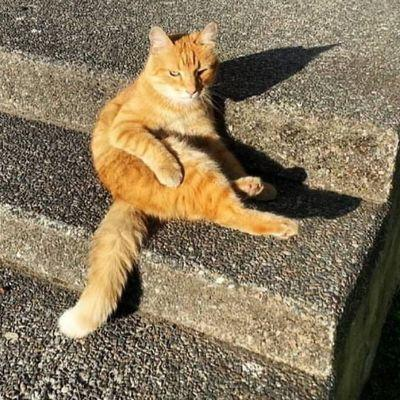

Question: What animal is visible in this image and how would you describe it?


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What animal is visible in this image and how would you describe it?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 722 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 16873 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 312 ms


Answer:  In the image, there is a cat sitting on a step. The cat is described as a large, orange, and fluffy cat. It appears to be relaxed and comfortable in its environment.


In [54]:
# Mode A demonstration
answer_mode_a = multimodal_qa(
    "image.jpg", "What animal is visible in this image and how would you describe it?"
)


# Final Laboratory Conclusion

The laboratory investigated how two vision-language systems handle image–text matching and image-conditioned response generation.

### CLIP findings

CLIP was applied to zero-shot categorization, prompt variations, and retrieval against a collection of images. The observed classification accuracy was **10/10 = 100%**. The top retrieval result for the football query was **images/class_69.jpg / 21.9%**.

### LLaVA findings

LLaVA produced responses to open-ended image questions. Human assessment accepted **19/25** answers, giving **76%**. The hallucination test showed one generated response require verification.

### Architectural comparison

CLIP uses contrastive alignment of image and text embeddings to score candidate descriptions. LLaVA uses visual representations within a language generation pipeline.

### Limitations and future directions

Our evidence comes from limited image samples, and the models were run in a CPU-only setting. Larger and more varied evaluations, faster inference hardware, and stronger verification of model claims would improve the experiment.

**Overall:** These exercises demonstrate why combining a retrieval-oriented vision-language encoder with a generative multimodal model is useful, while also highlighting the need to measure performance and check visual grounding.
